# Table 1 — Statistical asymmetry of prototypical sequences

This notebook regenerates Table 1 for four binary sequences of length
eight and a random-sequence ensemble with $p = 1/2$. White squares
represent 0 and black squares represent 1.

The columns $B_{C_N}$ and $B_{\mathbb{Z}_2}$ report statistical asymmetry
under cyclic translations and reflection, respectively. Each score uses
the distribution of Hamming distances between the original sequence and
its transformed copies, including the identity transformation. The
normalised entropy of that distribution is multiplied by the largest
observed distance divided by the sequence length.

The four fixed-sequence rows are calculated below. The random row
displays the published values. The note beneath the table gives the
exact expectations obtained by enumerating all 256 equally probable
binary sequences of length eight.

In [1]:
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle


def statistical_asymmetry(distances, sequence_length):
    _, counts = np.unique(distances, return_counts=True)
    probabilities = counts / len(distances)
    entropy = -np.sum(probabilities * np.log(probabilities))
    return (entropy / np.log(len(distances))) * (
        max(distances) / sequence_length
    )


def asymmetry_components(sequence):
    state = np.asarray(sequence)
    length = len(state)

    translation_distances = [
        np.count_nonzero(state != np.roll(state, shift))
        for shift in range(length // 2 + 1)
    ]
    reflection_distances = [0, np.count_nonzero(state != state[::-1])]

    return (
        statistical_asymmetry(translation_distances, length),
        statistical_asymmetry(reflection_distances, length),
    )


examples = ("00000000", "00001111", "01010101", "11000011")
rows = [
    (sequence, *asymmetry_components(tuple(map(int, sequence))))
    for sequence in examples
]

exact_translation, exact_reflection = np.mean(
    [asymmetry_components(state) for state in product((0, 1), repeat=8)],
    axis=0,
)

published_random = (0.466, 0.502)
rows.append((None, *published_random))

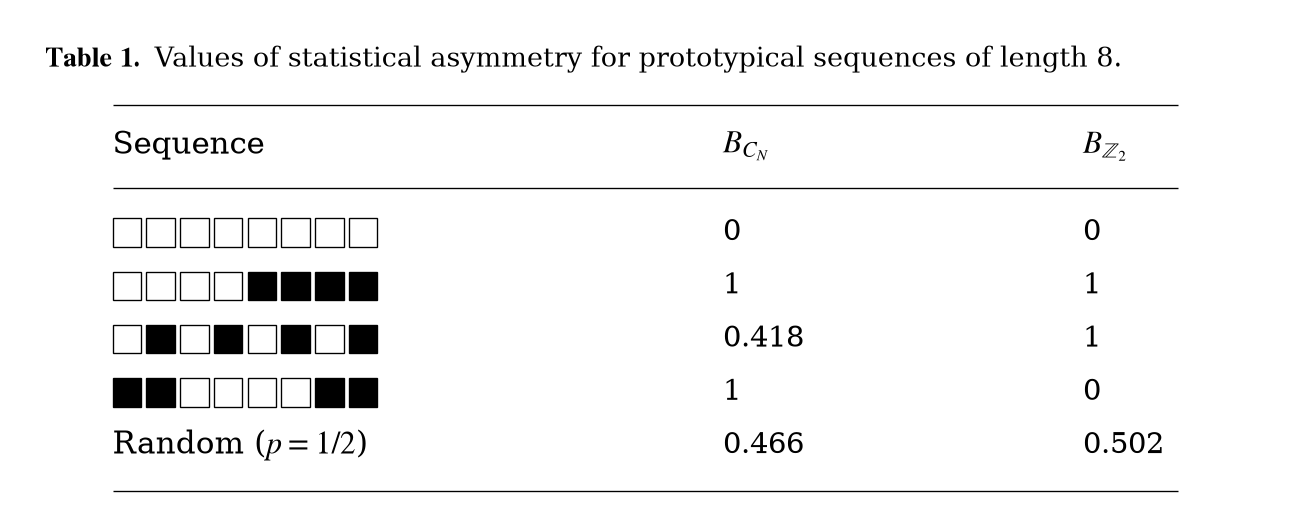

The random row gives the published values. Exact enumeration of all 256 equally probable sequences gives 0.467061 for translations and 0.500000 for reflection.

In [2]:
from IPython.display import Markdown, display


def format_score(value):
    if np.isclose(value, 0.0, rtol=0, atol=1e-12):
        return "0"
    if np.isclose(value, 1.0, rtol=0, atol=1e-12):
        return "1"
    return f"{value:.3f}"


with plt.rc_context({"font.family": "serif", "mathtext.fontset": "stix"}):
    fig, ax = plt.subplots(figsize=(8.4, 3.3), dpi=150)
    fig.patch.set_facecolor("white")
    ax.set_xlim(0, 8.4)
    ax.set_ylim(0, 3.3)
    ax.set_aspect("equal")
    ax.axis("off")

    ax.text(
        0.20, 3.00,
        r"$\mathbf{Table\ 1.}$ Values of statistical asymmetry for "
        "prototypical sequences of length 8.",
        fontsize=13,
        va="center",
    )

    left, right = 0.65, 7.75
    translation_x, reflection_x = 4.72, 7.12

    ax.hlines([2.70, 2.15, 0.13], left, right, color="black", linewidth=0.65)
    ax.text(left, 2.43, "Sequence", fontsize=15, va="center")
    ax.text(translation_x, 2.43, r"$B_{C_N}$", fontsize=15, va="center")
    ax.text(reflection_x, 2.43, r"$B_{\mathbb{Z}_2}$", fontsize=15, va="center")

    square_size = 0.19
    square_pitch = 0.225

    for row_index, (sequence, translation, reflection) in enumerate(rows):
        y = 1.85 - 0.355 * row_index

        if sequence is None:
            ax.text(left, y, r"Random ($p = 1/2$)", fontsize=15, va="center")
        else:
            for position, bit in enumerate(sequence):
                ax.add_patch(
                    Rectangle(
                        (left + position * square_pitch, y - square_size / 2),
                        square_size,
                        square_size,
                        facecolor="black" if bit == "1" else "white",
                        edgecolor="black",
                        linewidth=0.65,
                    )
                )

        ax.text(translation_x, y, format_score(translation), fontsize=14, va="center")
        ax.text(reflection_x, y, format_score(reflection), fontsize=14, va="center")

    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    plt.show()

display(Markdown(
    f"The random row gives the published values. Exact enumeration of all "
    f"256 equally probable sequences gives {exact_translation:.6f} for "
    f"translations and {exact_reflection:.6f} for reflection."
))